# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución
## GRUPO: Ax=b

# Integrantes
* Jano Bayarsky
* Ivan Flores

Importamos los módulos que vamos a utilizar:

In [116]:
from matplotlib import pyplot as plt
import cv2
import numpy as np
from alc import *
import pandas as pd

# Ejercicios:

### Ejercicio 1 - DLT ecuaciones formales

- Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

**Respuesta:**

Se busca resolver el sistema $Qm=0$.

Como $Q\in \mathbb{R}^{2n\times 12}$, necesitamos que $12 = \dim\operatorname{Nu}(Q) + \operatorname{rango}(Q)$ (por teorema de la dimensión).
Como se quiere que las soluciones estén a menos de un factor de escala, se pide que $\dim\operatorname{Nu}(Q) = 1$.
Despejando, se obtiene que el rango de $Q$ debe ser $11$.

Para tener un rango $11$, se requiere que la cantidad de puntos sea al menos $6$, ya que cada punto puede aportar a lo sumo dos al rango, y como $n\ge 6 \Rightarrow 2n\ge 12 \ge 11$.

Supongamos que existe un plano $ax+by+cz-d=0$ que contiene a todos los puntos. Entonces existe $v=(a,b,c,-d)\neq0$ tal que $v^\top P_i=0$ para todo $i$ (evaluar cada punto en la ecuación del plano la verifica). Por lo tanto, los vectores $(v,0,0)$ y $(0,v,0)$ de $\mathbb{R}^{12}$ cumplen $Qm=0$ y están en el núcleo de $Q$, con lo que $\dim\operatorname{Nu}(Q)>1$. Entonces los puntos no deben ser coplanares.

Los puntos de un mismo plano aportan en total a lo sumo $8$ al rango de $Q$, sin importar cuántos sean (los primeros $4$ aportan $2$ cada uno y los siguientes nada). Cada punto fuera de ese plano aporta a lo sumo $2$. Para llegar a rango $11$ hacen falta entonces al menos $2$ puntos fuera del plano, ya que $8+2=10<11$ pero $8+2+2=12\ge 11$. Por lo tanto, con $6$ puntos, a lo sumo $4$ pueden estar en un mismo plano.

- Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

**Respuesta:**

Queremos minimizar $\|Qm\|_2^2$, sujeto a $\|m\|_2 = 1$.

Calculo la SVD de $Q = U \Sigma V^\top$. Entonces $\|Qm\|_2^2 = \|U \Sigma V^\top m\|_2^2$. Como $U$ es ortogonal, esto es igual a $\|\Sigma V^\top m\|_2^2$. Renombrando al vector $V^\top m = y$, se tiene $\|\Sigma y\|_2^2$, y el vector $\Sigma y$ es igual a $(\sigma_1 y_1, \sigma_2 y_2, \dots, \sigma_{12} y_{12})$. Entonces

$$\|\Sigma y\|_2^2 = (\sigma_1 y_1)^2 + \dots + (\sigma_{12} y_{12})^2.$$

Cada $\sigma_i$ es mayor o igual que $\sigma_{12}$, así que esa suma es mayor o igual que

$$\sigma_{12}^2 \,(y_1^2 + y_2^2 + \dots + y_{12}^2) = \sigma_{12}^2 \|y\|_2^2.$$

Como $y = V^\top m$ y $V$ es ortogonal, $\|y\|_2^2 = \|m\|_2^2 = 1$ (lo pedimos antes de calcularlo). Recapitulando, llegamos a que

$$\|Qm\|_2^2 \ge \sigma_{12}^2 .$$

Para ver que esa cota se alcanza, volvemos a que $\|Qm\|_2^2 = \|\Sigma y\|_2^2$. Si tomamos $y = (0,0,\dots,1)$, entonces $\|\Sigma y\|_2^2 = \|(0,0,\dots,\sigma_{12})\|_2^2 = \sigma_{12}^2$. Recuperando la información original, $y = e_{12} = V^\top m$. Como $V^\top$ es ortogonal, $m = V e_{12}$, que es igual a tomar la última columna de $V$.

En conclusión, para hallar $m$, solamente basta con elegir la última columna de $V$, de la SVD de $Q$.

### Ejercicio 2 - Calibración con puntos 3D

Ejercicio de calibración de puntos 3D:

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para

b) $\alpha_u = \alpha_v$

c) $K_{12}=0$

Resolución:

In [117]:
#a)
det_corners = np.loadtxt('Archivos/calib/3d/detected_corners.txt')
u = det_corners[:,0::2]
v = det_corners[:,1::2]

real_corners = np.loadtxt('Archivos/calib/3d/p_W_corners.txt',delimiter=',')
Xw, Yw, Zw = real_corners[:,0], real_corners[:,1],real_corners[:,2]

k = 0
objPts = real_corners.copy()
imgPts = np.column_stack((u[k], v[k]))  # (12, 2): píxeles (u, v) de la imagen k

Q1 = obtenerQ3d(imgPts,objPts)
M1 = resolverDLT3D(Q1)
R,t,K = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=False)

#b
R_misma_focal,t_misma_focal,K_misma_focal = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=False)

#c
R_sin_skew,t_sin_skew,K_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=True)

#b y c
R_misma_focal_sin_skew,t_misma_focal_sin_skew,K_misma_focal_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=True)

In [118]:
np.set_printoptions(precision=4, suppress=True)

resultados = [
    ("a) Sin restricciones", K, R, t),
    ("b) Misma focal (au = av)", K_misma_focal, R_misma_focal, t_misma_focal),
    ("c) Sin sesgo (K12 = 0)", K_sin_skew, R_sin_skew, t_sin_skew),
    ("b y c) Misma focal y sin sesgo", K_misma_focal_sin_skew, R_misma_focal_sin_skew, t_misma_focal_sin_skew),
]

print("Imagen 0001 (k = 0)\n")

for titulo, K_i, R_i, t_i in resultados:
    print(f"{titulo}")
    print("K:\n", K_i)
    print("R:\n", R_i)
    print("t:\n", t_i.reshape(-1), "\n")

Imagen 0001 (k = 0)

a) Sin restricciones
K:
 [[425.8598  -0.0156 354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t:
 [-18.1679 -14.5033  40.5913] 

b) Misma focal (au = av)
K:
 [[425.2126  -0.0156 354.4185]
 [  0.     425.2126 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.355   0.9259 -0.1288]
 [ 0.7012  0.355   0.6183]]
t:
 [-18.1956 -14.4812  40.5913] 

c) Sin sesgo (K12 = 0)
K:
 [[425.8598   0.     354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t:
 [-18.1674 -14.5033  40.5913] 

b y c) Misma focal y sin sesgo
K:
 [[425.2126   0.     354.4185]
 [  0.     425.2126 256.8534]
 [  0.       0.       1.    ]]
R:
 [[ 0.6182  0.1292 -0.7753]
 [-0.355   0.9259 -0.1288]
 [ 0.7012  0.3551  0.6183]]
t:
 [-18.1951 -14.4812  40.5913] 



Reproyectamos los puntos, comparando los uv originales, de detected corners, con los obtenidos al multiplicar las distintas M por los puntos reales.

Como queremos transformar cada punto usando la matriz, ponemos a cada punto como columna, así que debemos tomar la matriz real_corners traspuesta.

In [119]:
R,t,K = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=False)

#b
R_misma_focal,t_misma_focal,K_misma_focal = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=False)

#c
R_sin_skew,t_sin_skew,K_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=False,sin_skew=True)

#b y c
R_misma_focal_sin_skew,t_misma_focal_sin_skew,K_misma_focal_sin_skew = devolverMatricesCalibracion3d(M1,misma_focal=True,sin_skew=True)

In [120]:
real_corners_con_unos = np.column_stack((real_corners, np.ones(12))).T

uv = obtener_uv_con_M(K,R,t,real_corners_con_unos)
uv_misma_focal = obtener_uv_con_M(K_misma_focal,R_misma_focal,t_misma_focal,real_corners_con_unos)
uv_sin_skew = obtener_uv_con_M(K_sin_skew,R_sin_skew,t_sin_skew,real_corners_con_unos)
uv_misma_focal_sin_skew = obtener_uv_con_M(K_misma_focal_sin_skew,R_misma_focal_sin_skew,t_misma_focal_sin_skew,real_corners_con_unos)

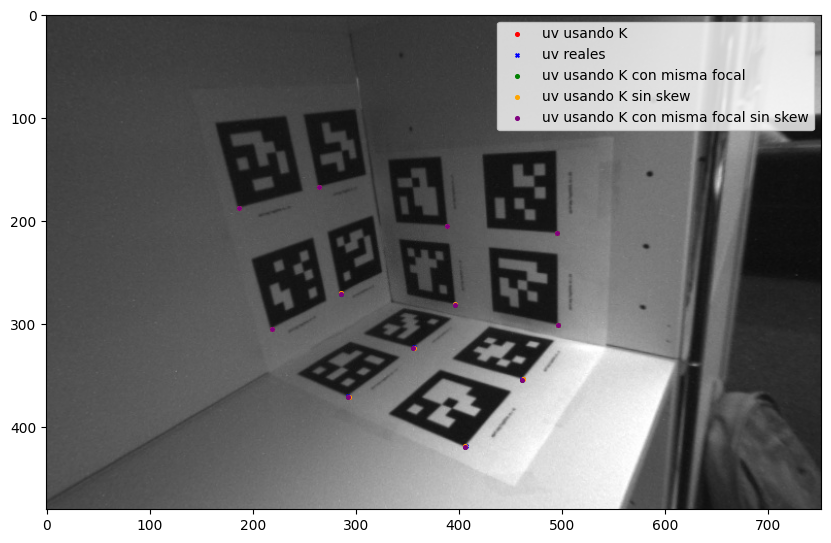

In [121]:
toma_1_3d = cv2.imread('Archivos/calib/3d/img_0001.jpg')
toma_1_3d = cv2.cvtColor(toma_1_3d, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(toma_1_3d)

plt.scatter(uv[:,0],uv[:,1], color="red", zorder=5,s=7,label='uv usando K')
plt.scatter(u[0,:],v[0,:], color="blue", s=7, zorder=5, marker='x',label='uv reales')
plt.scatter(uv_misma_focal[:,0],uv_misma_focal[:,1], color="green", zorder=5,s=7,label='uv usando K con misma focal')
plt.scatter(uv_sin_skew[:,0],uv_sin_skew[:,1], color="orange", zorder=5,s=7,label='uv usando K sin skew')
plt.scatter(uv_misma_focal_sin_skew[:,0],uv_misma_focal_sin_skew[:,1], color="purple", zorder=5,s=7,label='uv usando K con misma focal sin skew')

plt.legend()
plt.show()

No se llegan a apreciar las diferencias, pero si se ejecuta cada color por separado se ve que todos corresponden a las esquinas.

Los cálculos de K, R y t parecen buenos, vamos a comprobar si es asi.

In [122]:

for nombre, uv_i in [("a) original", uv), ("b) misma focal", uv_misma_focal),
                     ("c) sin skew", uv_sin_skew), ("b y c", uv_misma_focal_sin_skew)]:
    media, maximo = error_reproy(uv_i, u[0,:], v[0,:])
    print(f"{nombre}: error medio {media:.3f} px, máximo {maximo:.3f} px")

a) original: error medio 0.331 px, máximo 0.745 px
b) misma focal: error medio 0.476 px, máximo 1.008 px
c) sin skew: error medio 0.332 px, máximo 0.746 px
b y c: error medio 0.476 px, máximo 1.010 px


In [123]:
print("Alfa u: ",K[0][0])
print("Alfa v: ",K[1][1])
print("Skew: ",K[0][1])

Alfa u:  425.859843138067
Alfa v:  424.5652955878349
Skew:  -0.01563966658871323


Sin restricciones, la calibración da αu = 425.86, αv = 424.57 y K12 = -0.016.
El skew estimado es prácticamente nulo (0.004 % de αu), por lo que imponer
K12 = 0 casi no modifica el error de reproyección (a y c dan prácticamente
lo mismo). Las focales difieren en 1.29 px (~0.3 %); forzar αu = αv
(f = 425.21) aumenta el error medio de 0.331 a 0.473 px (+43 % relativo,
+0.14 px absolutos). Como se ve en la figura, los cuatro conjuntos de puntos se superponen con las esquinas reales.
Imponer ambas restricciones da un resultado
similar al de b). Estos resultados corresponden a la imagen 0001.

### Ejercicio 3 - Calibración con puntos coplanares

Ejercicio de calibración de puntos coplanares:

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.

a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

Resolución:

a)

Vamos a realizar una calibración de puntos coplanares para verificar que las funciones implementadas hagan lo esperado. Tomando 20 imagenes de un tablero de ajedrez, visto desde distíntos ángulos, queremos determinar los parámetros de la cámara y de las distintas poses.

Las esquinas internas del tablero tienen coordenadas (30 i, 30 j) mm, con i = 0,...,10 y j = 0,...,6.
Determinamos que la esquina superior interna izquierda tiene coordenadas (30x0,30x0)mm = (0,0)mm. L esquina inferior interna derecha (30x10,30x6)mm = (300,180)mm.

Para construir la matriz Q, $Q\in \mathbb{R}^{2n\times 9}$, por el teorema de la dimensión, pedimos que Dim(Nu(Q)) + Rango(Q) = 9. Como queremos que tenga solución única a menos de un factor de escala, el núcleo debe tener dimensión 1.

Por lo tanto, Rango(Q) = 9 - 1 = 8. Como vimos en la calibración de puntos 3D, cada punto suma dos al rango. Como se busca que el rango sea 8, se necesitan 4 puntos para poder realizar la calibración.

Como sabemos que con 4 puntos nos alcanza para obtener la matriz Hj de cada toma, seleccionamos las 4 esquinas más externas del tablero de todas las tomas. Seleccionamos los puntos con paint y los registramos en un Excel, de la siguiente forma:

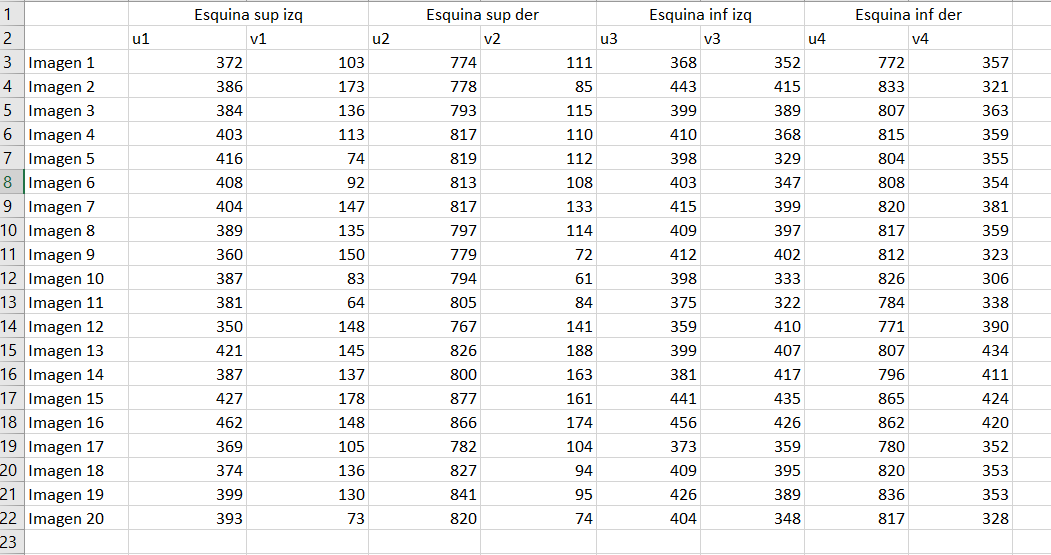

In [124]:
puntos_imagen_calib_cop = pd.read_excel("puntos_tablero_calibracion_coplanares.xlsx", skiprows=2, header=None, usecols="B:I").to_numpy()
puntos_imagen_calib_cop.shape

(20, 8)

In [125]:
u_cop = puntos_imagen_calib_cop[:,0::2]
v_cop = puntos_imagen_calib_cop[:,1::2]

pts_tablero = np.array([
    [0, 0], # Esquina superior izquierda
    [300, 0], # Esquina superior derecha
    [0, 180], # Esquina infeior izquierda
    [300, 180]  # Esquina inferior derecha
], dtype=float)
# Las columnas representan las coordenadas U, V

In [126]:
Hlist = []
for j in range(20):
    objPts = pts_tablero.copy()
    imgPts = np.column_stack((u_cop[j], v_cop[j]))
    Qj = obtenerQ2d(imgPts,objPts)
    Hj = resolver2D(Qj)
    Hlist.append(Hj)

Hlist tiene una lista con los indices j=0 a 19, en los que cada posición devuelve la matriz de la imagen j+1 (j=19 corresponde a la imagen 20)

In [152]:
A = armarA(Hlist)
K = calcularMatrizK2D(A)
K

c:\Users\janob\OneDrive\Escritorio\Reentrega TP ALC\alc.py:299: RuntimeWarning: invalid value encountered in sqrt
  D_raiz = np.diag(np.sqrt(np.diag(D)))


array([[nan, nan, nan],
       [nan, nan, nan],
       [nan, nan, nan]])

b)

Ahora falta hallar la pose de las imágenes 1,10 y 20

In [ ]:
R1,t1 = obtenerPose2D(Hlist[0], K)
R10,t10 = obtenerPose2D(Hlist[9], K)
R20,t20 = obtenerPose2D(Hlist[19], K)

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo.
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

Calculamos la distancia de Enzo al arco en el momento de patear:

In [128]:
img = cv2.imread("Archivos/futbol/test-gol-enzo.png")
if img is None:
    raise FileNotFoundError("No se pudo leer la imagen, revisá la ruta")

imgPts =  np.array([
            [510, 320],
            [651, 184],
            [383, 175],
            [842, 189],
            [196, 171],
            [865, 252],
            [156, 233]
        ])

objPts = np.array([[94,34],
                   [105,30.34],
                   [105,37.66],
                   [105,24.84],
                   [105,43.16],
                   [99.5,24.84],
                   [99.5,43.16]
                   ])

In [129]:
Q = obtenerQ2d(imgPts,objPts)
H = resolver2D(Q)

pieEnzo = (807,540)

dist = distGolEnzo(pieEnzo,H)
print(dist)

23.049493067433758


Trazamos un círculo al rededor de los jugadores argentinos:

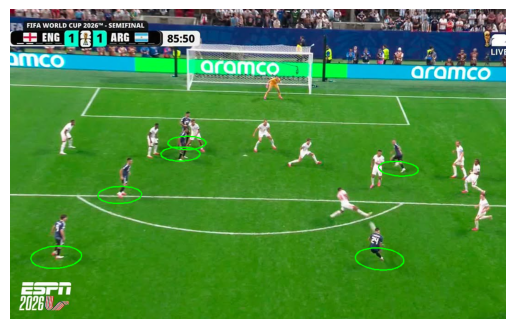

In [130]:
#Ubicar jugadores argentinos
posJugadores = np.array([
    [101, 539],
    [239, 404],
    [371, 315],
    [385, 291],
    [804, 543],
    [845, 347]
])

H_inv = inversa(H)

img = cv2.imread("Archivos/futbol/test-gol-enzo.png")
assert img is not None, "no se encontró la imagen"


for pos in posJugadores:
    U,V = proyectar(H_inv,pos[0],pos[1])
    dibujar_circulo(img,H,U,V)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$.
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.

Para construir H necesitamos elegir al menos 4 puntos, de forma que ninguna de las filas de la matriz sea linealmente dependiente de las demás.

Elegimos 9 puntos con una separacion considerable entre sí. Los puntos reales de la cancha se eligieron tomando como referencia los datos del Estadio Azteca, y los puntos de la imagen los seleccionamos utilizando Paint, poniendo el cursor sobre el pixel buscado y registrando su valor.

En coordenadas reales, el area grande del lado derecho está en x=88,5; el area grande en x=99,5.
Desde el medio de la cancha (respecto a y), el arco tiene 3,66 mts para cada lado; 9,16 el área chica; y 20,16 el área grande.
La linea lateral superior está en y=0; la linea de fondo derecha en x=105.

In [131]:
puntos_cancha = np.array([
    [105,0],
    [105,(68/2)-(40.32/2)],
    [105,(68/2)-(18.32/2)],
    [105,(68/2)-(7.32/2)],
    [105-5.5,(68/2)-(18.32/2)],
    [105-5.5,(68/2)+(18.32/2)],
    [105-16.5,(68/2)-(40.32/2)],
    [105-16.5,(68/2)+(40.32/2)],

])

puntos_imagen = np.array([
    [1306, 235],
    [1388, 311],
    [1475, 387],
    [1524, 433],
    [1231, 391],
    [1365, 575],
    [735, 317],
    [736, 755],
])

Para obtener la matriz H, se debe descomponer Q en SVD, y tomar la última columna de V (o última fila de V traspuesta), que será igual a la matriz h (los elementos de la matriz H puestos como vector)

In [132]:
Q = obtenerQ2d(puntos_imagen,puntos_cancha)
H = resolver2D(Q)

Verificamos que esté bien calculada con algunos puntos:

In [133]:
puntos_cancha_aux = []

for punto in puntos_cancha:
    punto = np.append(punto, 1)
    puntos_cancha_aux.append(punto)

puntos_cancha_aux = np.array(puntos_cancha_aux)

for punto in puntos_cancha_aux:
    print (calcularAx(H,punto))

[0.5482 0.0989 0.0004]
[0.5096 0.1139 0.0004]
[0.4789 0.1258 0.0003]
[0.4636 0.1318 0.0003]
[0.3982 0.1263 0.0003]
[0.3471 0.1461 0.0003]
[0.2672 0.1152 0.0004]
[0.1548 0.1589 0.0002]


In [134]:
# Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor
for punto in puntos_cancha_aux:
    punto_im = calcularAx(H,punto)
    punto_im = punto_im / punto_im[-1]
    print (punto_im)

[1306.5005  235.7995    1.    ]
[1388.9803  310.4942    1.    ]
[1473.6113  387.1369    1.    ]
[1524.6693  433.3757    1.    ]
[1229.1413  389.7692    1.    ]
[1365.5074  574.7428    1.    ]
[734.91   316.8432   1.    ]
[736.8701 756.0114   1.    ]


Los pixeles obtenidos son bastante cercanos a los de la imagen.

El pie del penúltimo jugador del otro equipo está en el pixel (827,327) aproximadamente. Lo pasamos a Coordenadas del mundo real con la inversa de H, y tomamos el punto que está a altura 0 con el mismo valor de x, y entre ellos trazamos la linea

In [135]:
inv_H = inversa(H)
pixel_pie = [827,327,1]
posicion_pie = calcularAx(inv_H,pixel_pie)
print(posicion_pie)

[253871.0008  43539.9048   2797.0905]


Como queremos que la ultima coord del punto de la imagen sea 1, dividimos por ese valor

In [136]:
posicion_pie = posicion_pie / posicion_pie[-1]
print(posicion_pie)

[90.7625 15.5661  1.    ]


El pie está en x = 90,76.
Para trazar una recta paralela a la linea de fondo, buscamos el pixel correspondiente a la posición del mundo real (90.76,0), que es la posicion correspondiente al mismo valor de x sobre la linea lateral superior. Usamos la homografía para encontrar este valor.

In [137]:
segundo_punto = calcularAx(H,[90.76,0,1])
print(segundo_punto)
segundo_punto = segundo_punto / segundo_punto[-1]
print(segundo_punto)

[0.339  0.1001 0.0004]
[813.435  240.0773   1.    ]


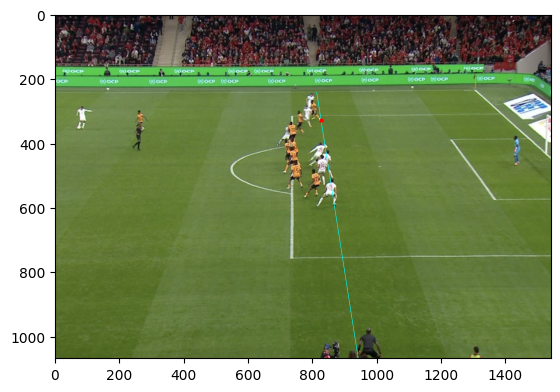

In [138]:
u1, v1, _ = pixel_pie
u2, v2, _ = segundo_punto

fuera_de_juego = cv2.imread('Archivos/futbol/test-fuera-de-juego.png')
fuera_de_juego = cv2.cvtColor(fuera_de_juego, cv2.COLOR_BGR2RGB)
plt.imshow(fuera_de_juego)

m = (v2 - v1) / (u2 - u1)
b = v1 - m * u1
alto_img, ancho_img = fuera_de_juego.shape[0], fuera_de_juego.shape[1]

v_fin = alto_img - 1
u_fin = u2 + (v_fin - v2) / m

plt.scatter(u1,v1, color="red", s=4, zorder=5)

plt.plot([u2, u_fin], [v2, v_fin], color="cyan", linewidth=0.4)

plt.xlim(0, ancho_img)
plt.ylim(alto_img, 0)

plt.show()

Trazamos la linea de offside, marcamos con un punto rojo el apoyo del pie del jugador del otro equipo sobre ella.
Se puede ver que al menos dos jugadores del equipo blanco están adelantados: El de abajo de todo tiene casi medio cuerpo adelantado, y hay otro que tiene la pierna adelantada. Hay otro que está sobre la linea, pero parece ser que está habilitado ya tiene en brazo adelantado unicamente

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [139]:
df = pd.read_csv('Archivos/salguero/world_img_pts.csv', sep=";")
display(df)
display(df.shape)
data = df.values

,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


(5, 12)

Como tenemos únicamente 5 puntos para realizar la calibración, no se puede realizar la de puntos 3D: Vamos a pensar el problema como uno de puntos coplanares. De esta forma se van a tener más que 4 puntos, que es lo necesario para realizar este tipo de calibración.

Al tener varias tomas distintas, podemos aprovechar esta información para calcular distintos Hj para armar la matriz A, y con ella la matriz K. Habiendo obtenido la matriz K, y para una vista Hj determinada, podemos calcular el valor de la pose de la cámara (los parámetros Rj y tj).

In [140]:
XY = data[:, 1:3]
u = data[:, 4:12:2]
v = data[:, 5:12:2]

In [141]:
lista_H = []
for i in range(4):
    ui = u[:,i]
    vi = v[:,i]

    objPts = XY
    imgPts = np.column_stack((ui, vi))

    Q = obtenerQ2d(imgPts, objPts)
    Hj = resolver2D(Q)
    lista_H.append(Hj)

A = armarA(lista_H)
K = calcularMatrizK2D(A).T
print(K)

[[  2782.7801  17702.8087 804474.7903]
 [     0.        213.0557  41679.4551]
 [     0.         -0.          1.    ]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

In [142]:
puntos_primera_imagen = np.loadtxt('Archivos/salguero/gs_10_09_point_correspondences_v5.txt',delimiter='	')

En este caso todos los z valen 0, asi que nuevamente se usa el modelo de puntos coplanares.

In [143]:
XY, uv = (
    puntos_primera_imagen[1:3,:],
    puntos_primera_imagen[4:,:],

)

XY = XY.T
uv = uv.T

print(XY.shape)
print(uv.shape)

(51, 2)
(51, 2)


Calculamos la matriz Hj específica para esta toma, y se aprovecha el calculo de los parámetros intrínsecos (K) en el item anterior para estimar Rj y tj.

In [144]:
Q = obtenerQ2d(uv,XY)
Hj = resolver2D(Q)
Rj,tj = obtenerPose2D(Hj, K)

Para proyectar tenemos que usar la homografía con las coords del mundo real. Tomamos XY, que tiene tamaño 51x2, le agregamos una tercera columna de unos, que representa la tercera coord de cada punto, y trasponemos. Esto es porque necesitamos que los puntos o las matrices que sean transformados por H, deben tener 3 filas (H tiene 3 columnas)

In [145]:
XY_con_unos_traspuesta = np.column_stack((XY, np.ones(51))).T
uv_calculados_trasp = multiplicarMatrices(Hj,XY_con_unos_traspuesta)
uv_calculados = uv_calculados_trasp.T
uv_calculados = (uv_calculados / uv_calculados[:, -1:])[:,0:2]
uv_calculados.shape

(51, 2)

Proyectamos los puntos u,v reales y los calculados con la homografía para ver si la transformación es precisa:

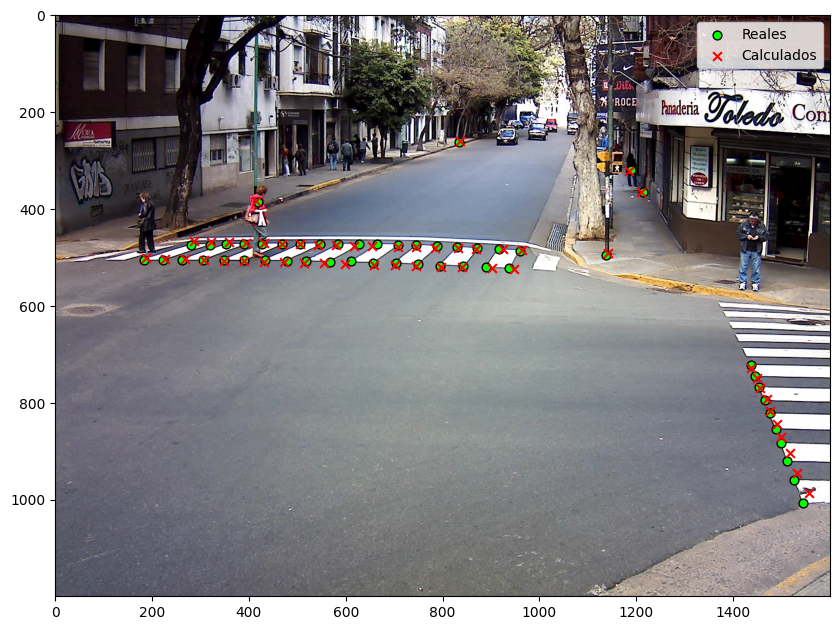

In [146]:
u_real = uv[:,0]
v_real = uv[:,1]
u_calc = uv_calculados[:,0]
v_calc = uv_calculados[:,1]

imagen_salguero = cv2.imread('Archivos/salguero/img_10_18_47_351.jpg')
imagen_salguero = cv2.cvtColor(imagen_salguero, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(imagen_salguero)

plt.scatter(u_real, v_real, c='lime', label='Reales', s=40, edgecolors='black')

plt.scatter(u_calc, v_calc, c='red', marker='x', label='Calculados', s=40)

plt.legend()
plt.show()

A excepción de algunos puntos, la mayoría de las aproximaciones se parecen bastante a los originales, por lo que la homografía es precisa.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

Tenemos 46 tomas, y todas tienen la misma posición de la cámara, y comparten el parámetro intrínseco. Elegimos tratarla como se fuera una única imagen que tiene distintos puntos.

El segundo final es el 52.546, y el inicial el 47,351. El lapso es de 5,195 segundos. Vamos a usar 6 tomas distribuidas de forma uniforme entre la primera y la ultima para tener un frame cada un segundo aproximadamente, ya que se asume que la separación temporal entre una toma y la siguiente es similar para todas.

Se eligen las imágenes 1,10,19,28,37,46.

Im1: img_10_18_47_351.jpg

Im10: img_10_18_48_350.jpg

Im19: img_10_18_49_582.jpg

Im28: img_10_18_50_534.jpg

Im37: img_10_18_51_563.jpg

Im46: img_10_18_52_546.jpg


In [147]:
señora_px = np.array([[418,501],[544,495],[695,490],[814,490],[909,489],[989,489]])
taxi_px = np.array([[933,267],[900,283],[835,307],[756,350],[612,419],[299,577]])
camioneta_px = np.array([[995,258],[988,270],[972,288],[941,317],[891,361],[788,445]])
segundos = np.array([47.351,48.350,49.582,50.534,51.563,52.546])

Nuevamente los u,v se seleccionaron mediante Paint.

En el b se calculó la pose de la cámara para la imagen img_10_18_47_351.jpg, que es la misma que la primera de estas 6. Por lo tanto ya se tiene K,Rj y tj para esa imagen y las otras 5.

Se utiliza esta información para construir H, y pasar de las coordenadas en pantalla a las coordenadas reales, así calculamos las velocidades.
Las mismas serán entre los intervalos 1-10, 10-19, 19-28, 28-37, 37-46. Cada una se va a calcular como la norma 2 de (xf,yf)-(xi,yf) (la variación de la distancia), y dividimos por el segundo final menos el segundo inicial. Vamos a tomar la velocidad que se pide en la consigna como el promedio de estas 5 velocidades.

In [148]:
np.set_printoptions(suppress=True, precision=10)

v_señora = obtener_velocidad_kmh(señora_px, Hj, segundos)
v_taxi = obtener_velocidad_kmh(taxi_px, Hj, segundos)
v_camioneta = obtener_velocidad_kmh(camioneta_px, Hj, segundos)

Graficamos el promedio de velocidades entre 5 intervalos equiespaciados de todas las imágenes

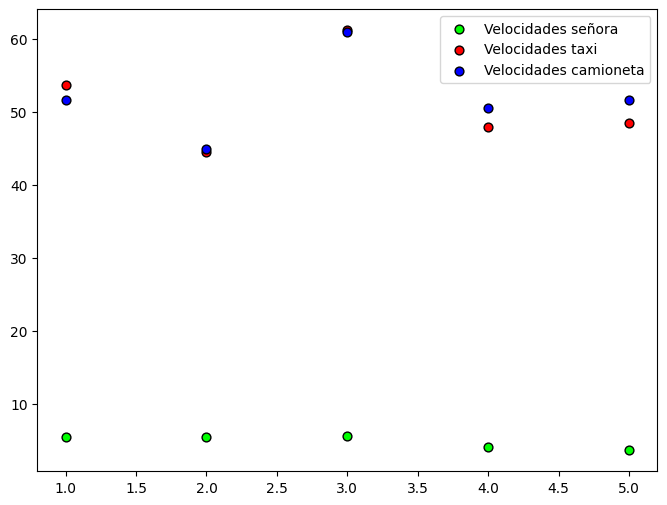

In [149]:
intervalos_tiempo = np.arange(1,6)

plt.figure(figsize=(8, 6))

plt.scatter(intervalos_tiempo,v_señora, c='lime', label='Velocidades señora', s=40, edgecolors='black')
plt.scatter(intervalos_tiempo,v_taxi, c='red', label='Velocidades taxi', s=40, edgecolors='black')
plt.scatter(intervalos_tiempo,v_camioneta, c='blue', label='Velocidades camioneta', s=40, edgecolors='black')
plt.legend()
plt.show()

In [150]:
datos = {
    "señora": v_señora,
    "taxi": v_taxi,
    "camioneta": v_camioneta
}

for objeto_persona, velocidades in datos.items():
    promedio = np.mean(velocidades)
    desvio = np.std(velocidades)
    desvio_porcentual = (desvio / promedio) * 100

    print(f"Velocidad minima {objeto_persona}: {np.min(velocidades):.2f} km/h")
    print(f"Velocidad maxima {objeto_persona}: {np.max(velocidades):.2f} km/h")
    print(f"Velocidad promedio {objeto_persona}: {promedio:.2f} km/h")
    print(f"Desvio estandar {objeto_persona}: {desvio:.2f} km/h ({desvio_porcentual:.2f}% del promedio)\n")

Velocidad minima señora: 3.64 km/h
Velocidad maxima señora: 5.56 km/h
Velocidad promedio señora: 4.86 km/h
Desvio estandar señora: 0.81 km/h (16.57% del promedio)

Velocidad minima taxi: 44.58 km/h
Velocidad maxima taxi: 61.22 km/h
Velocidad promedio taxi: 51.21 km/h
Desvio estandar taxi: 5.81 km/h (11.34% del promedio)

Velocidad minima camioneta: 44.99 km/h
Velocidad maxima camioneta: 61.00 km/h
Velocidad promedio camioneta: 51.98 km/h
Desvio estandar camioneta: 5.15 km/h (9.90% del promedio)



Nuevamente aclaramos que estos datos son estimaciones con unos pocos datos de todo el conjunto; no son literalmente el minimo, el maximo y el promedio. Usamos el desvio estandar ya que es una medida que nos permite ver qué tanto se alejan los datos de la media. Puede ocurrir que para valores chicos o grandes, no se llegue a apreciar qué representa este valor. Por eso tomamos el desvío estandar porcentual.

### Ejercicio 6 - Aterrizaje suave
Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$.

a)

In [151]:
# Coordenadas reales de los cinco puntos de la H, en metros
centro_real = (0.0, 0.0, 0.0)
sup_izq_real = (-0.175, 0.3, 0.0)
sup_der_real = (0.175, 0.3, 0.0)
inf_der_real = (0.175, -0.3, 0.0)
inf_izq_real = (-0.175, -0.3, 0.0)

puntos_reales = np.array([
    centro_real,
    sup_izq_real,
    sup_der_real,
    inf_der_real,
    inf_izq_real
])

# Coordenadas en pixeles de los mismos puntos
centro_px = (526, 1007)
sup_izq_px = (402, 1097)
sup_der_px = (392, 944)
inf_der_px = (644, 913)
inf_izq_px = (656, 1061)

puntos_px = np.array([
    centro_px,
    sup_izq_px,
    sup_der_px,
    inf_der_px,
    inf_izq_px
])

# Cargamos la matriz de parametros intrinsecos
K = np.loadtxt("Archivos/heli/K.csv", delimiter=";")